In [2]:
pip install tavily-python

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\HP\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [1]:
!pip install langchain langchain-community ddgs langchain_groq

Defaulting to user installation because normal site-packages is not writeable
  Using cached langsmith-0.3.45-py3-none-any.whl.metadata (15 kB)
  Using cached langsmith-0.2.11-py3-none-any.whl.metadata (14 kB)
INFO: pip is looking at multiple versions of langchain-core to determine which version is compatible with other requirements. This could take a while.
  Using cached langchain_core-0.3.84-py3-none-any.whl.metadata (3.2 kB)
  Using cached langchain_core-0.3.79-py3-none-any.whl.metadata (3.2 kB)
INFO: pip is still looking at multiple versions of langchain-core to determine which version is compatible with other requirements. This could take a while.
  Using cached langchain_core-0.3.78-py3-none-any.whl.metadata (3.2 kB)
  Using cached langchain_core-0.3.77-py3-none-any.whl.metadata (3.2 kB)
  Using cached langchain_core-0.3.76-py3-none-any.whl.metadata (3.7 kB)
  Using cached langchain_core-0.3.75-py3-none-any.whl.metadata (5.7 kB)
  Using cached langchain_core-0.3.74-py3-none-any.

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langchain-google-genai 4.1.2 requires langchain-core<2.0.0,>=1.2.2, but you have langchain-core 0.3.63 which is incompatible.

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\HP\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [10]:
from dotenv import load_dotenv
import os

load_dotenv()

GROQ_API_KEY=os.getenv('GROQ_API_KEY')
Tavily_Api_Key=os.getenv('Tavily_Api_key')


print("Apis are getting loaded")

Apis are getting loaded


In [11]:
from langchain_groq import ChatGroq

In [12]:
Model = ChatGroq(
    model='openai/gpt-oss-20b',
    api_key=GROQ_API_KEY
)

In [13]:
Model.invoke("What are 2+2").content

'2\u202f+\u202f2\u202f=\u202f4.'

In [7]:
!pip install tavily

Defaulting to user installation because normal site-packages is not writeable
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for tavily: filename=tavily-1.1.0-py3-none-any.whl size=6143 sha256=624a7a07e7b38c2193c5d9ad53bf0cd6ccd2c5af77d1c291aa58e082f74ffd76
  Stored in directory: c:\users\hp\appdata\local\pip\cache\wheels\a7\67\b7\9aec4851724de28ac2bc34ff10b042af43d7f2dd1552e5906e
Successfully built tavily



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\HP\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [14]:
from tavily import TavilyClient
tavily_client = TavilyClient(api_key=Tavily_Api_Key)
response = tavily_client.search("Who is Leo Messi?")

print(response['results'])

[{'url': 'https://en.wikipedia.org/wiki/Lionel_Messi', 'title': 'Lionel Messi - Wikipedia', 'content': 'Lionel Andrés "Leo" Messi (born 24 June 1987) is an Argentine professional footballer who plays as a forward "Forward (association football)") for and captains "Captain (association football)") the Major League Soccer club Inter Miami. Widely regarded as one of the greatest players in history, he played for the Argentina national team for 21 years. During his career, he has set numerous records for individual accolades won, including eight Ballons d\'Or, six European Golden Shoes, and being [...] the Argentine Armed Forces. On his father\'s side, Messi is of Italian and Spanish descent, the great-grandson of immigrants from the Marche region of Italy (with his surname coming from Porto Recanati), and on his mother\'s side he has primarily Italian ancestry. Growing up in a tight-knit, football-loving family, "Leo" developed a passion for the sport from an early age, playing constantly

In [15]:
from typing import TypedDict,Optional,Annotated
from pydantic import BaseModel,Field
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages

In [16]:
class MessageState(TypedDict):
  messages : Annotated[list[AnyMessage],add_messages]

In [17]:
from langchain_core.tools import tool
from tavily import TavilyClient

In [18]:
@tool
def tavily_search(query:str):
  """Search the internet for current information.
     Use this tool when user asks about latest news,
     recent updates, or information available online."""
  try:
    response = tavily_client.search(query,max_results=3)
    return str(response['results'])
  except Exception as e:
    return str(e)

In [19]:
from ddgs import DDGS

@tool
def duckduckgo_search(query: str) -> str:
    """
    Search the internet using DuckDuckGo.
    Use this tool to find information, tutorials,
    technical documentation and general web content.
    """

    client = DDGS()

    try:
        response = client.text(
            query,
            max_results=5
        )
        return str(response)

    except Exception as e:
        return str(e)

In [20]:
@tool
def mathematics_calculation(expression:str):
  '''Use this tool to perform mathematics calculations'''
  try:
    result = eval(expression)
    return str(result)
  except Exception as e:
    return str(e)

In [21]:
print(mathematics_calculation.invoke({
    "expression": "25000 * 0.15"
}))

3750.0


# Bind tool with model

In [22]:
Model_With_Tools = Model.bind_tools([tavily_search,duckduckgo_search,mathematics_calculation])

In [23]:
from langgraph.prebuilt import ToolNode,tools_condition


tool_node = ToolNode([tavily_search,duckduckgo_search,mathematics_calculation])

In [18]:
pip install -U langgraph-checkpoint-postgres "psycopg[binary,pool]"

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.9 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.9 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.9 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.9 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.9 MB ? eta -:--:--
   ------- -------------------------------- 0.5/2.9 MB 250.4 kB/s eta 0:00:10
   ------- -------------------------------- 0.5/2.9 MB 250.4 kB/s eta 0:00:10
   ------- -------------------------------- 0.5/2.9 MB 250.4 kB/s eta 0:00:1

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langgraph 0.2.64 requires langgraph-checkpoint<3.0.0,>=2.0.10, but you have langgraph-checkpoint 4.3.2 which is incompatible.

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\HP\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [25]:
import psycopg
from getpass import getpass

password = getpass("PostgreSQL password: ")

try:
    conn = psycopg.connect(
        host="localhost",
        port=5432,
        dbname="langgraph_testing_database",
        user="postgres",
        password=password
    )

    print("PostgreSQL Connected Successfully!")

    conn.close()

except Exception as e:
    print("Error:", e)

finally:
    del password

PostgreSQL Connected Successfully!


In [28]:
%pip install --ignore-installed --no-deps langgraph-checkpoint==4.3.2

Defaulting to user installation because normal site-packages is not writeable
  Using cached langgraph_checkpoint-4.3.2-py3-none-any.whl.metadata (6.7 kB)
Using cached langgraph_checkpoint-4.3.2-py3-none-any.whl (58 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\HP\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [26]:
import sys

print("Python Version:", sys.version)
print("Python Executable:", sys.executable)

Python Version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Python Executable: C:\Users\HP\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe


In [26]:
from langgraph.checkpoint.postgres import PostgresSaver
from psycopg_pool import ConnectionPool
from getpass import getpass
from urllib.parse import quote_plus

password = quote_plus(getpass("PostgreSQL password: "))

DB_URI = (
    f"postgresql://postgres:{password}"
    f"@localhost:5432/langgraph_testing_database"
)

In [27]:
connection_kwargs = {
    "autocommit": True,
    "prepare_threshold": 0,
}

pool = ConnectionPool(
    conninfo=DB_URI,
    min_size=1,
    max_size=5,
    kwargs=connection_kwargs,
)

checkpointer = PostgresSaver(pool)

checkpointer.setup()

print("PostgreSQL Checkpointer Setup Successful!")

PostgreSQL Checkpointer Setup Successful!


In [28]:
from langgraph.graph import START,END,StateGraph
graph = StateGraph(MessageState)

In [35]:
def agent(state:MessageState):
   response = Model_With_Tools.invoke(
        state["messages"]
    )
   return {
        "messages": [response]
    }

In [39]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition

graph = StateGraph(MessageState)


graph.add_node("agent", agent)
graph.add_node("tools", ToolNode([tavily_search,duckduckgo_search,mathematics_calculation]))


graph.add_edge(START, "agent")

graph.add_conditional_edges(
    "agent",
    tools_condition
)

graph.add_edge("tools", "agent")

workflow = graph.compile(
    checkpointer=checkpointer
)

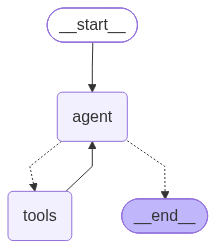

In [42]:
from IPython.display import display,Image

try:
  image_data = workflow.get_graph().draw_mermaid_png()
  display(Image(data=image_data))
except Exception as e:
  print(e)

In [43]:
from langchain_core.messages import HumanMessage

config = {
    "configurable": {
        "thread_id": "waris_001"
    }
}

response = workflow.invoke(
    {
        "messages": [
            HumanMessage(content="My name is Waris and I am an AI Engineer.")
        ]
    },
    config=config
)

print(response["messages"][-1].content)

Nice to meet you, Waris! As an AI Engineer, you’re probably already familiar with how conversational models work. If you have any questions, want to discuss AI topics, or need help with a project, feel free to let me know!


In [44]:
response = workflow.invoke(
    {
        "messages": [
            HumanMessage(content="What is my name and profession?")
        ]
    },
    config=config
)

print(response["messages"][-1].content)

You’re Waris, and you’re an AI Engineer.


In [52]:
from langchain_core.messages import HumanMessage
config = {
    'configurable':{
        'thread_id': '123456789'
    }
}

while True:

    user_input = input("You: ")

    if user_input.lower() == "exit":
        break

    response = workflow.invoke({
        "messages": [
            HumanMessage(content=user_input)
        ]
    },config=config)

    for message in response["messages"]:

        print("\nMessage Type:", type(message).__name__)
        print("Content:", message.content)

        if hasattr(message, "tool_calls") and message.tool_calls:
            print("Tool Calls:", message.tool_calls)

You: hello do you know about my name

Message Type: HumanMessage
Content: hello do you know about my name

Message Type: AIMessage
Content: I don’t actually know what your name is—could you let me know? Or if you’re looking for information about a specific name, just tell me which one and I’ll help!
You: my name is waris my first name is waris and last name is hayat and if i talk about my family name that is abbasi

Message Type: HumanMessage
Content: hello do you know about my name

Message Type: AIMessage
Content: I don’t actually know what your name is—could you let me know? Or if you’re looking for information about a specific name, just tell me which one and I’ll help!

Message Type: HumanMessage
Content: my name is waris my first name is waris and last name is hayat and if i talk about my family name that is abbasi

Message Type: AIMessage
Content: Sure! Here’s a quick rundown of the names you mentioned, along with some background on their meanings, origins, and a few notable peo

In [53]:
saved_state = workflow.get_state(config)

In [71]:
print(saved_state.values)

{'messages': [HumanMessage(content='hello do you know about my name', additional_kwargs={}, response_metadata={}, id='c1df32dd-9a6f-41a1-ad74-fcee3e4fd140'), AIMessage(content='I don’t actually know what your name is—could you let me know? Or if you’re looking for information about a specific name, just tell me which one and I’ll help!', additional_kwargs={'reasoning_content': 'The user says "hello do you know about my name". They might be asking if I know their name. I don\'t have that info. I should respond politely and ask what name or clarify. No need for internet.'}, response_metadata={'token_usage': {'completion_tokens': 92, 'prompt_tokens': 211, 'total_tokens': 303, 'completion_time': 0.094694979, 'completion_tokens_details': {'reasoning_tokens': 45}, 'prompt_time': 0.010381083, 'prompt_tokens_details': None, 'queue_time': 0.113588819, 'total_time': 0.105076062}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_f102a3179c', 'service_tier': 'on_demand', 'finish_reaso